# Stock feature preparation and expanding monthly training

Prospective development study: four fixed RAW-target arms, all original cohorts, 96 monthly predictions and94 mature paired months. The fresh six-column reference must match the original saved float64 predictions exactly. This draft has no executed outputs; only the actual cloud-executed copy may become a public result.


In [1]:
"""Stdlib-only prospective notebook input authentication; no provider mutations.

The stager must render ROOT_PLAN_SHA256 from an actual reviewed source/data
freeze. Unbound source refuses before package extraction or native imports.
All four whole input bundles and every member are authenticated before the
locked environment helper or any project module is imported.
"""

import hashlib
import importlib.util
import json
import math
import shutil
import stat
import subprocess
import tempfile
import time
import zipfile
from datetime import UTC, datetime
from pathlib import Path, PurePosixPath

ROOT_PLAN_SHA256 = "7c4f4661d6a85e6afc649e928dc44217cdfcf2b37d2f17e7e7fb0b1f90c43a8a"
INPUT_ROLES = ("original_market", "original_prepared_panel", "original_raw_reference")


def _require(value, message):
    if not value:
        raise ValueError(message)


def _budget(deadline):
    if not math.isfinite(deadline) or time.monotonic() >= deadline:
        raise TimeoutError("Startup-inclusive wider notebook service deadline")


def _sha(path, deadline):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        while block := stream.read(4 * 1024 * 1024):
            _budget(deadline)
            digest.update(block)
    return digest.hexdigest()


def _safe_relative(name):
    path = PurePosixPath(name)
    _require(
        isinstance(name, str)
        and name
        and "\\" not in name
        and not path.is_absolute()
        and all(p not in ("", ".", "..") for p in path.parts)
        and ":" not in name,
        "Unsafe bound member path",
    )
    return path


def _regular(path, root):
    _require(path.resolve().is_relative_to(root.resolve()), "Input path escapes root")
    _require(
        path.is_file() and not any(p.is_symlink() for p in (path, *path.parents)),
        "Regular contained input file required",
    )


def discover_bound(root, *, sha256, size=None, suffix=None, filename=None, deadline):
    """Recursive exact SHA/size unique discovery, never first-match mounting."""
    root, matches = Path(root), []
    _require(
        isinstance(sha256, str)
        and len(sha256) == 64
        and all(c in "0123456789abcdef" for c in sha256),
        "Externally bound SHA required",
    )
    for path in root.rglob("*"):
        _budget(deadline)
        if not path.is_file() or (suffix is not None and path.suffix != suffix):
            continue
        if filename is not None and path.name != filename:
            continue
        if size is not None and path.stat().st_size != size:
            continue
        _regular(path, root)
        if _sha(path, deadline) == sha256:
            matches.append(path)
    _require(len(matches) == 1, "Exactly one bound input required")
    return matches[0]


def _write(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("x", encoding="utf-8", newline="\n") as stream:
        json.dump(value, stream, indent=2, sort_keys=True, allow_nan=False)
        stream.write("\n")


def _inspect(container, members, deadline):
    expected = {r["path"]: r for r in members}
    _require(len(expected) == len(members), "Duplicate bound input members")
    with zipfile.ZipFile(container) as archive:
        entries = archive.infolist()
        _require(
            len(entries) == len(expected) and {e.filename for e in entries} == set(expected),
            "Exact whole bundle inventory required",
        )
        for entry in entries:
            _budget(deadline)
            _safe_relative(entry.filename)
            _require(
                not entry.is_dir()
                and not stat.S_ISLNK(entry.external_attr >> 16)
                and not entry.flag_bits & 1,
                "Regular unencrypted bundle members required",
            )
            item = expected[entry.filename]
            _require(entry.file_size == item["bytes"], "Bundle member size mismatch")
            digest = hashlib.sha256()
            with archive.open(entry) as stream:
                while block := stream.read(4 * 1024 * 1024):
                    _budget(deadline)
                    digest.update(block)
            _require(digest.hexdigest() == item["sha256"], "Bundle member SHA mismatch")


def _extract(container, members, root, deadline):
    root.mkdir(parents=True, exist_ok=False)
    with zipfile.ZipFile(container) as archive:
        for item in members:
            target = root / _safe_relative(item["path"])
            target.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(item["path"]) as source, target.open("xb") as out:
                while block := source.read(4 * 1024 * 1024):
                    _budget(deadline)
                    out.write(block)
            _require(_sha(target, deadline) == item["sha256"], "Extracted input SHA mismatch")


def run(input_root, output_root):
    """Authenticate inputs, create locked interpreter/context; no prepare or fit."""
    started, output = time.monotonic(), Path(output_root)
    output.mkdir(parents=True, exist_ok=False)
    _write(
        output / "STARTED.json",
        {"actual_started_at": datetime.now(UTC).isoformat(), "complete": False},
    )
    try:
        deadline = started + 36000
        plan_path = discover_bound(
            input_root, sha256=ROOT_PLAN_SHA256, suffix=".json", deadline=deadline
        )
        plan = json.loads(plan_path.read_bytes())
        _require(set(plan["roots"]) == set(INPUT_ROLES), "All three exact input roots required")
        for value in plan["roots"].values():
            if value != ".":
                _safe_relative(value)
        _require(
            plan["schema"] == "quant_stock_wider_notebook_plan_v1"
            and plan["private"] is True
            and plan["service_seconds"] == 36000
            and plan["holdout_evaluated"] is False,
            "Frozen private wider notebook plan required",
        )
        _require(
            set(plan["data_inputs"]) == set(INPUT_ROLES),
            "Exactly original market/prepared/reference plus source dataset required",
        )
        _require(
            plan["source_approval"]["status"] == "READY"
            and plan["source_approval"]["schema"] == "quant_stock_wider_source_freeze_v1",
            "Actual root source approval required",
        )
        production = {
            item["path"]: {"bytes": item["bytes"], "sha256": item["sha256"]}
            for item in plan["source_files"]
            if item["path"] != "reference/metrics.json"
        }
        _require(
            production == plan["source_approval"]["production_inventory"]
            and plan["runtime"] == plan["source_approval"]["runtime"]
            and plan["data_freeze_sha256"] == plan["source_approval"]["data_freeze_sha256"],
            "Approved exact source/runtime/data closure required",
        )
        _require(
            all(
                plan["data_freezes"][role]["status"] == "READY"
                and plan["data_bindings"][role]["private"] is True
                and type(plan["data_bindings"][role]["dataset_id"]) is int
                and plan["data_bindings"][role]["dataset_id"] > 0
                and plan["data_bindings"][role]["version"] == 1
                for role in INPUT_ROLES
            ),
            "Actual positive private numeric-version data freezes required",
        )
        source_paths = {}
        for item in plan["source_files"]:
            name = str(_safe_relative(item["path"]))
            _require(name not in source_paths, "Duplicate source package path")
            source_paths[name] = discover_bound(
                input_root,
                sha256=item["sha256"],
                size=item["bytes"],
                filename=item["package_name"],
                deadline=deadline,
            )
        containers = {}
        for role, item in plan["data_inputs"].items():
            container = discover_bound(
                input_root, sha256=item["sha256"], size=item["bytes"], deadline=deadline
            )
            _inspect(container, item["members"], deadline)
            containers[role] = container
        # Every whole BIN and every member passed before project/native imports.
        required_tmp = (
            sum(m["bytes"] for item in plan["data_inputs"].values() for m in item["members"])
            + 8 * 1024**3
        )
        _require(
            plan["minimum_free_tmp_bytes"] == required_tmp
            and shutil.disk_usage("/tmp").free >= required_tmp,
            "Insufficient verified private input/runtime disk budget",
        )
        private = Path(tempfile.mkdtemp(prefix="quantlab-wider-", dir="/tmp"))
        project = private / "project"
        for name, path in source_paths.items():
            destination = project / name
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(path.read_bytes())
        for item in plan["source_files"]:
            _require(
                _sha(project / item["path"], deadline) == item["sha256"],
                "Materialized source changed",
            )
        for role, item in plan["data_inputs"].items():
            _extract(containers[role], item["members"], private / role, deadline)
        derived = plan["derived_reference_metrics"]
        metrics_source = project / _safe_relative(derived["source_path"])
        _require(
            derived["source_path"] in source_paths
            and _sha(metrics_source, deadline) == derived["sha256"]
            and metrics_source.stat().st_size == derived["bytes"],
            "Original hash-bound derived reference metrics required",
        )
        reference_root = (
            private / "original_raw_reference" / plan["roots"]["original_raw_reference"]
        )
        reference_manifest = reference_root / "manifest.json"
        _require(
            _sha(reference_manifest, deadline) == plan["reference_manifest_sha256"],
            "Original b46 reference manifest required before metrics restoration",
        )
        reference_inventory = json.loads(reference_manifest.read_bytes())["artifacts"]
        _require(
            any(
                item["path"] == "metrics.json" and item["sha256"] == derived["sha256"]
                for item in reference_inventory
            ),
            "Derived metrics differ from b46 inventory",
        )
        with (reference_root / "metrics.json").open("xb") as stream:
            stream.write(metrics_source.read_bytes())
        helper_path = project / "cloud/stock_development_runner.py"
        _require(
            "cloud/stock_development_runner.py" in source_paths,
            "Hash-bound locked-runtime helper required",
        )
        spec = importlib.util.spec_from_file_location("wider_locked_runtime", helper_path)
        helper = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(helper)
        locked, environment, actual_runtime = helper.bootstrap_with_receipt(
            private, project, output, deadline
        )
        _require(Path(locked).is_file(), "Actual locked interpreter path required")
        # Notebook plotting is a declared locked research dependency, not an
        # opportunistic import from the provider's unrelated base environment.
        subprocess.run(
            [
                str(private / "uv-package/bin/uv"),
                "sync",
                "--locked",
                "--no-install-project",
                "--no-default-groups",
                "--group",
                "ml",
                "--group",
                "research",
                "--project",
                str(project),
                "--python",
                actual_runtime["managed_interpreter"],
            ],
            check=True,
            env=environment,
            timeout=helper.remaining_budget(deadline),
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
        )
        context = {
            "project": str(project),
            "startup_deadline_monotonic": deadline,
            "normalized_manifest_sha256": plan["normalized_manifest_sha256"],
            "source_plan_sha256": ROOT_PLAN_SHA256,
            "runtime": plan["runtime"],
            "locked_interpreter": str(locked),
            "private_managed_root": str(private / "python"),
            "project_source_sha256": {
                item["path"]: item["sha256"] for item in plan["source_files"]
            },
            "input_container_sha256": {
                str(containers[role]): item["sha256"] for role, item in plan["data_inputs"].items()
            },
            "market_root": str(private / "original_market" / plan["roots"]["original_market"]),
            "prepared_root": str(
                private / "original_prepared_panel" / plan["roots"]["original_prepared_panel"]
            ),
            "reference_root": str(
                private / "original_raw_reference" / plan["roots"]["original_raw_reference"]
            ),
            "wider_root": str(output / "wider-panel"),
            "study_root": str(output / "stock-wider-study"),
            "artifact_root": str(output / "figures"),
        }
        for value in plan["roots"].values():
            if value != ".":
                _safe_relative(value)
        Path(context["artifact_root"]).mkdir()
        context_path = private / "notebook-context.json"
        _write(context_path, context)
        _budget(deadline)
        _write(
            output / "notebook-bootstrap-receipt.json",
            {
                "complete": False,
                "input_authentication_complete": True,
                "source_plan_sha256": ROOT_PLAN_SHA256,
                "roles": list(INPUT_ROLES),
                "runtime_bootstrap": actual_runtime,
                "scientific_study_complete": False,
            },
        )
        return str(locked), str(context_path), environment
    except BaseException as error:
        _write(
            output / "FAILURE.json",
            {
                "complete": False,
                "phase": "wider_notebook_bootstrap",
                "error_type": type(error).__name__,
                "message": str(error)[:1000],
            },
        )
        raise

LOCKED_PYTHON, CONTEXT_PATH, LOCKED_ENV = run('/kaggle/input', '/kaggle/working/wider-run')


In [2]:
import hashlib, json, os, subprocess, sys
from pathlib import Path
assert Path('/kaggle/working').is_dir(), 'Cloud notebook only'
assert Path(LOCKED_PYTHON).is_file() and Path(CONTEXT_PATH).is_file()
CONTEXT_SHA = hashlib.sha256(Path(CONTEXT_PATH).read_bytes()).hexdigest()
def run_locked(code):
    # Each visible cell below really executes this exact code in the locked
    # interpreter. There are no pasted logs, cached training outputs or host fits.
    env = LOCKED_ENV.copy()
    env['QUANTLAB_WIDER_CONTEXT'] = str(CONTEXT_PATH)
    env['QUANTLAB_WIDER_CONTEXT_SHA'] = CONTEXT_SHA
    try:
        result = subprocess.run([str(LOCKED_PYTHON), '-c', code], env=env, check=True)
    except BaseException as error:
        context = json.loads(Path(CONTEXT_PATH).read_bytes())
        failure = Path(context['artifact_root']).parent / 'NOTEBOOK_FAILURE.json'
        failure.write_text(json.dumps({'complete':False, 'error_type':type(error).__name__})+'\n')
        raise
    return result.returncode


## Authenticate the full source population and original decision cohorts
No current-survivor screen, no added-feature readiness filter, no label value whose maturity is after the 2014 information cutoff.


In [3]:
run_locked(r'''
import hashlib, json, os, time
from datetime import date
from pathlib import Path
context_raw = Path(os.environ['QUANTLAB_WIDER_CONTEXT']).read_bytes()
assert hashlib.sha256(context_raw).hexdigest() == os.environ['QUANTLAB_WIDER_CONTEXT_SHA']
context = json.loads(context_raw)
deadline = context['startup_deadline_monotonic']
def check_input_sources():
    paths = {str(Path(context['project'])/p): s for p,s in context['project_source_sha256'].items()}
    paths.update(context['input_container_sha256'])
    for name, expected_sha in paths.items():
        digest = hashlib.sha256()
        with Path(name).open('rb') as stream:
            while block := stream.read(4*1024*1024):
                assert time.monotonic() < deadline
                digest.update(block)
        assert digest.hexdigest() == expected_sha, 'Source/input postflight mismatch'
check_input_sources()
import platform, sys
from importlib.metadata import version
assert platform.python_version() == '3.12.15'
assert Path(os.path.abspath(sys.executable)) == Path(context['locked_interpreter'])
managed_root = Path(context['private_managed_root']).resolve()
assert Path(sys.executable).resolve().is_relative_to(managed_root)
assert {name:version(name) for name in context['runtime']} == context['runtime']
from quantlab.data.calendar import XNYSSchedule
from quantlab.stocks import development as d
from quantlab.stocks.wider_panel import PARENT_SHA
schedule = XNYSSchedule(date(1962,1,1), date(2018,12,31))
assert time.monotonic() < deadline
base_path = Path(context['project']) / 'configs/stock-development.toml'
base = d.load_spec(base_path)
from quantlab.data.snapshot import MarketSnapshot
from quantlab.stocks.ablation import authenticate_reference
snapshot = MarketSnapshot(context['market_root'], context['normalized_manifest_sha256'])
parent = d.verify_prepared_panel(context['prepared_root'], PARENT_SHA)
reference, old_metrics, old_fits = authenticate_reference(context['reference_root'], base)
data = d.read_development_inputs(context['prepared_root'], PARENT_SHA, base, schedule)
print('Full upstream population:', parent['counts'])
print('Original training feature rows:', len(data.features),
      'Original decision dates:', len(data.decision_times))
print('Original reference prediction dates:', len(reference))
print('Clock-rejected outcome partitions:', data.outcome_value_partitions_refused)
assert data.full_research_scope and len(reference) == 96

check_input_sources()
''')


Full upstream population: {'candidates_rows': 1539730, 'empty_source_histories': 32, 'features_rows': 88309, 'labels_rows': 1539730, 'source_histories_read': 7195, 'source_rows_read': 14887665}
Original training feature rows: 71309 Original decision dates: 180
Original reference prediction dates: 96
Clock-rejected outcome partitions: ('labels/2014-11-28.parquet', 'labels/2014-12-31.parquet', 'labels/2015-01-30.parquet', 'labels/2015-02-27.parquet', 'labels/2015-03-31.parquet', 'labels/2015-04-30.parquet', 'labels/2015-05-29.parquet', 'labels/2015-06-30.parquet', 'labels/2015-07-31.parquet', 'labels/2015-08-31.parquet', 'labels/2015-09-30.parquet', 'labels/2015-10-30.parquet', 'labels/2015-11-30.parquet', 'labels/2015-12-31.parquet', 'labels/2016-01-29.parquet', 'labels/2016-02-29.parquet', 'labels/2016-03-31.parquet', 'labels/2016-04-29.parquet', 'labels/2016-05-31.parquet', 'labels/2016-06-30.parquet', 'labels/2016-07-29.parquet', 'labels/2016-08-31.parquet', 'labels/2016-09-30.parque

0

## Actual past-only feature window and formula examples
The window is observed source data. F22-F25 remain proof-gated; observed volume features have conditional source units and make no capacity claim.


In [4]:
run_locked(r'''
import hashlib, json, os, time
from datetime import date
from pathlib import Path
context_raw = Path(os.environ['QUANTLAB_WIDER_CONTEXT']).read_bytes()
assert hashlib.sha256(context_raw).hexdigest() == os.environ['QUANTLAB_WIDER_CONTEXT_SHA']
context = json.loads(context_raw)
deadline = context['startup_deadline_monotonic']
def check_input_sources():
    paths = {str(Path(context['project'])/p): s for p,s in context['project_source_sha256'].items()}
    paths.update(context['input_container_sha256'])
    for name, expected_sha in paths.items():
        digest = hashlib.sha256()
        with Path(name).open('rb') as stream:
            while block := stream.read(4*1024*1024):
                assert time.monotonic() < deadline
                digest.update(block)
        assert digest.hexdigest() == expected_sha, 'Source/input postflight mismatch'
check_input_sources()
import platform, sys
from importlib.metadata import version
assert platform.python_version() == '3.12.15'
assert Path(os.path.abspath(sys.executable)) == Path(context['locked_interpreter'])
managed_root = Path(context['private_managed_root']).resolve()
assert Path(sys.executable).resolve().is_relative_to(managed_root)
assert {name:version(name) for name in context['runtime']} == context['runtime']
from quantlab.data.calendar import XNYSSchedule
from quantlab.stocks import development as d
from quantlab.stocks.wider_panel import PARENT_SHA
schedule = XNYSSchedule(date(1962,1,1), date(2018,12,31))
assert time.monotonic() < deadline
base_path = Path(context['project']) / 'configs/stock-development.toml'
base = d.load_spec(base_path)
from quantlab.data.snapshot import MarketSnapshot
from quantlab.stocks.wider_features import wider_candidate_from_history
snapshot = MarketSnapshot(context['market_root'], context['normalized_manifest_sha256'])
with snapshot.verified_read_session() as verified:
    bars = verified.bars('stock', 'IBM')
    candidate = wider_candidate_from_history('stock:ibm.us', bars, schedule,
        as_of=date(2010,1,29), archive_sha256=snapshot.archive_sha256)
assert candidate.original.eligible and len(candidate.original.source_rows) == 253
print('Actual window:', candidate.original.source_rows[0].session,
      candidate.original.source_rows[-1].session)
for value in candidate.values:
    print(value.feature_id, value.value, value.missing_reason, value.units)

check_input_sources()
''')


Actual window: 2009-01-29 2010-01-29
F01 0.42540907207953604 None dimensionless_observed_source_ratio
F02 0.11882214274101766 None dimensionless_observed_source_ratio
F03 0.03312302839116721 None dimensionless_observed_source_ratio
F04 0.007590694006309073 None dimensionless_observed_source_ratio
F05 -0.02313601709757651 None dimensionless_observed_source_ratio
F06 0.024713740458015332 None dimensionless_observed_source_ratio
F07 0.07174643538279912 None dimensionless_observed_source_ratio
F08 0.20786868011159448 None annualised_log_return_standard_deviation_252
F09 0.162011354936697 None annualised_log_return_standard_deviation_252
F10 0.12153766825756696 None annualised_log_downside_semideviation_252
F11 0.2830500688844644 None dimensionless_observed_source_ratio
F12 -0.6173082682910066 None uncorrected_log_return_moment_skewness
F13 -0.04243957279370436 None dimensionless_observed_source_ratio
F14 0.0892392369575703 None dimensionless_observed_source_ratio
F15 -0.0874921881974825 No

0

## Prepare all original training cohorts with added observed predictors
This is the full preparation operation, not a displayed cached panel. Original parent raw-six bytes, source-row digests and clocks are retained exactly. Only the exact full-cohort audited F09/F19 whitelist can record a platform difference.


In [5]:
run_locked(r'''
import hashlib, json, os, time
from datetime import date
from pathlib import Path
context_raw = Path(os.environ['QUANTLAB_WIDER_CONTEXT']).read_bytes()
assert hashlib.sha256(context_raw).hexdigest() == os.environ['QUANTLAB_WIDER_CONTEXT_SHA']
context = json.loads(context_raw)
deadline = context['startup_deadline_monotonic']
def check_input_sources():
    paths = {str(Path(context['project'])/p): s for p,s in context['project_source_sha256'].items()}
    paths.update(context['input_container_sha256'])
    for name, expected_sha in paths.items():
        digest = hashlib.sha256()
        with Path(name).open('rb') as stream:
            while block := stream.read(4*1024*1024):
                assert time.monotonic() < deadline
                digest.update(block)
        assert digest.hexdigest() == expected_sha, 'Source/input postflight mismatch'
check_input_sources()
import platform, sys
from importlib.metadata import version
assert platform.python_version() == '3.12.15'
assert Path(os.path.abspath(sys.executable)) == Path(context['locked_interpreter'])
managed_root = Path(context['private_managed_root']).resolve()
assert Path(sys.executable).resolve().is_relative_to(managed_root)
assert {name:version(name) for name in context['runtime']} == context['runtime']
from quantlab.data.calendar import XNYSSchedule
from quantlab.stocks import development as d
from quantlab.stocks.wider_panel import PARENT_SHA
schedule = XNYSSchedule(date(1962,1,1), date(2018,12,31))
assert time.monotonic() < deadline
base_path = Path(context['project']) / 'configs/stock-development.toml'
base = d.load_spec(base_path)
from quantlab.data.snapshot import MarketSnapshot
from quantlab.stocks.wider_panel import prepare_wider_panel
from quantlab.stocks.feature_reproduction import POLICY, POLICY_SHA256, DIAGNOSTIC_SHA256
from quantlab.stocks.wider_study import load_spec as load_wider_spec
wider_spec_path = Path(context['project'])/'configs/stock-wider-development.toml'
portability = load_wider_spec(wider_spec_path)['feature_reproduction']
assert portability['policy_sha256'] == POLICY_SHA256
assert portability['diagnostic_sha256'] == DIAGNOSTIC_SHA256
snapshot = MarketSnapshot(context['market_root'], context['normalized_manifest_sha256'])
prepared = prepare_wider_panel(snapshot, context['prepared_root'], schedule,
    context['wider_root'], service_deadline_monotonic=deadline,
    reproduction_policy=POLICY, reproduction_parent_platform=portability['parent_platform'])
print('Wider preparation completed:', prepared['decision_count'],
      'dates;', prepared['feature_rows'], 'unchanged selected rows')
print('Exact whitelisted F09/F19 representation differences:',
      len(prepared['accepted_feature_representation_differences']))

check_input_sources()
''')


Wider preparation completed: 180 dates; 71309 unchanged selected rows
Exact whitelisted F09/F19 representation differences: 896


0

## Mature training labels and equal date influence
Training expands only through labels available at each signal cutoff. Sample weights are inverse rows per date, normalized to mean one.


In [6]:
run_locked(r'''
import hashlib, json, os, time
from datetime import date
from pathlib import Path
context_raw = Path(os.environ['QUANTLAB_WIDER_CONTEXT']).read_bytes()
assert hashlib.sha256(context_raw).hexdigest() == os.environ['QUANTLAB_WIDER_CONTEXT_SHA']
context = json.loads(context_raw)
deadline = context['startup_deadline_monotonic']
def check_input_sources():
    paths = {str(Path(context['project'])/p): s for p,s in context['project_source_sha256'].items()}
    paths.update(context['input_container_sha256'])
    for name, expected_sha in paths.items():
        digest = hashlib.sha256()
        with Path(name).open('rb') as stream:
            while block := stream.read(4*1024*1024):
                assert time.monotonic() < deadline
                digest.update(block)
        assert digest.hexdigest() == expected_sha, 'Source/input postflight mismatch'
check_input_sources()
import platform, sys
from importlib.metadata import version
assert platform.python_version() == '3.12.15'
assert Path(os.path.abspath(sys.executable)) == Path(context['locked_interpreter'])
managed_root = Path(context['private_managed_root']).resolve()
assert Path(sys.executable).resolve().is_relative_to(managed_root)
assert {name:version(name) for name in context['runtime']} == context['runtime']
from quantlab.data.calendar import XNYSSchedule
from quantlab.stocks import development as d
from quantlab.stocks.wider_panel import PARENT_SHA
schedule = XNYSSchedule(date(1962,1,1), date(2018,12,31))
assert time.monotonic() < deadline
base_path = Path(context['project']) / 'configs/stock-development.toml'
base = d.load_spec(base_path)
import math
from quantlab.stocks.ablation import authenticate_reference
reference, _, _ = authenticate_reference(context['reference_root'], base)
data = d.read_development_inputs(context['prepared_root'], PARENT_SHA, base, schedule)
day = min(reference)
cutoff = dict(data.decision_times)[day]
batch = d.training_batch(data, day, cutoff, base)
assert batch.ready and batch.max_label_available_at <= cutoff
mass = {}
for row, weight in zip(batch.feature_rows, batch.weights, strict=True):
    mass.setdefault(str(row.signal_session), []).append(weight)
masses = [math.fsum(v) for v in mass.values()]
print('First actual fit:', day, cutoff, 'rows:', len(batch.feature_rows),
      'dates:', len(batch.date_counts), 'latest mature label:', batch.max_label_available_at)
print('Raw training SHA:', batch.input_sha256)
print('Weight mean:', math.fsum(batch.weights)/len(batch.weights),
      'date-mass min/max:', min(masses), max(masses))

check_input_sources()
''')


First actual fit: 2007-01-31 2007-01-31 21:01:00+00:00 rows: 23975 dates: 83 latest mature label: 2007-01-03 21:01:00+00:00
Raw training SHA: 914fa33ab296ca56da64d70700c48f48569b30a95495f43986a612b124b3986e
Weight mean: 1.0 date-mass min/max: 288.855421686747 288.85542168674704


0

## Construct, fit and predict the fixed learner
The following actual estimator code runs in the locked interpreter for all384 fits. The orchestrator validates its exact AST against the reviewed function, uses unchanged RAW targets and date weights, seals each prediction before joining current outcomes, and emits every completed date/arm checkpoint.


In [7]:
training_source = r'''import hashlib, json, os, time
from datetime import date
from pathlib import Path
context_raw = Path(os.environ['QUANTLAB_WIDER_CONTEXT']).read_bytes()
assert hashlib.sha256(context_raw).hexdigest() == os.environ['QUANTLAB_WIDER_CONTEXT_SHA']
context = json.loads(context_raw)
deadline = context['startup_deadline_monotonic']
def check_input_sources():
    paths = {str(Path(context['project'])/p): s for p,s in context['project_source_sha256'].items()}
    paths.update(context['input_container_sha256'])
    for name, expected_sha in paths.items():
        digest = hashlib.sha256()
        with Path(name).open('rb') as stream:
            while block := stream.read(4*1024*1024):
                assert time.monotonic() < deadline
                digest.update(block)
        assert digest.hexdigest() == expected_sha, 'Source/input postflight mismatch'
check_input_sources()
import platform, sys
from importlib.metadata import version
assert platform.python_version() == '3.12.15'
assert Path(os.path.abspath(sys.executable)) == Path(context['locked_interpreter'])
managed_root = Path(context['private_managed_root']).resolve()
assert Path(sys.executable).resolve().is_relative_to(managed_root)
assert {name:version(name) for name in context['runtime']} == context['runtime']
from quantlab.data.calendar import XNYSSchedule
from quantlab.stocks import development as d
from quantlab.stocks.wider_panel import PARENT_SHA
schedule = XNYSSchedule(date(1962,1,1), date(2018,12,31))
assert time.monotonic() < deadline
base_path = Path(context['project']) / 'configs/stock-development.toml'
base = d.load_spec(base_path)

def fit_predict_visible(parameters, matrix, targets, weights, prediction_matrix):
    """Actual fixed estimator construction/fit/predict, shown in the main notebook."""
    from pathlib import Path

    if not Path("/kaggle/working").is_dir() or not Path("/kaggle/input").is_dir():
        raise ValueError("Native wider estimator fitting is restricted to Kaggle")
    import numpy as np
    from lightgbm import LGBMRegressor
    from threadpoolctl import threadpool_limits

    with threadpool_limits(limits=4):
        model = LGBMRegressor(**dict(parameters))
        model.fit(
            np.asarray(matrix, dtype=float),
            np.asarray(targets, dtype=float),
            sample_weight=np.asarray(weights, dtype=float),
        )
        predicted = model.predict(np.asarray(prediction_matrix, dtype=float))
    return model, predicted
from quantlab.data.archive import file_sha256
from quantlab.stocks.wider_study import run_wider_study, validate_visible_fit
print('Visible estimator source certificate:', validate_visible_fit(fit_predict_visible))
print('Fixed recipe: L1,15 leaves,100 trees; four feature arms; RAW target;4 threads')
result = run_wider_study(context['prepared_root'], context['wider_root'],
    file_sha256(Path(context['wider_root'])/'manifest.json'), base_path,
    Path(context['project'])/'configs/stock-wider-development.toml', schedule,
    context['reference_root'], context['study_root'],
    service_deadline_monotonic=deadline, visible_fit_callback=fit_predict_visible)
print('Actual full study:', result)
check_input_sources()
'''
training_path = Path(CONTEXT_PATH).parent / 'visible-wider-training.py'
with training_path.open('x', encoding='utf-8', newline='\n') as stream:
    stream.write(training_source)
run_locked("import runpy; runpy.run_path(" + repr(str(training_path)) + ", run_name='__main__')")


Visible estimator source certificate: f9a57d277236c22a40c2ed0a275c01f48151d9ab8e430892acac34a8b826676d
Fixed recipe: L1,15 leaves,100 trees; four feature arms; RAW target;4 threads
Completed actual wider cell 1/384 2007-01-31 fresh_six_reference
Completed actual wider cell 2/384 2007-01-31 add_five_union_eleven
Completed actual wider cell 3/384 2007-01-31 documented_compact_ten
Completed actual wider cell 4/384 2007-01-31 all_supported_twenty_one
Completed actual wider cell 5/384 2007-02-28 fresh_six_reference
Completed actual wider cell 6/384 2007-02-28 add_five_union_eleven
Completed actual wider cell 7/384 2007-02-28 documented_compact_ten
Completed actual wider cell 8/384 2007-02-28 all_supported_twenty_one
Completed actual wider cell 9/384 2007-03-30 fresh_six_reference
Completed actual wider cell 10/384 2007-03-30 add_five_union_eleven
Completed actual wider cell 11/384 2007-03-30 documented_compact_ten
Completed actual wider cell 12/384 2007-03-30 all_supported_twenty_one
Comple

0

## Full paired development results and coverage
All four arms and all94 mature months are reported together. Nov/Dec2014 unresolved labels remain explicit; no holdout, partial-grid winner or reliable edge claim is implied. Uncertainty is a separate later analysis.


{
  "common_mature_dates": [
    "2007-01-31",
    "2007-02-28",
    "2007-03-30",
    "2007-04-30",
    "2007-05-31",
    "2007-06-29",
    "2007-07-31",
    "2007-08-31",
    "2007-09-28",
    "2007-10-31",
    "2007-11-30",
    "2007-12-31",
    "2008-01-31",
    "2008-02-29",
    "2008-03-31",
    "2008-04-30",
    "2008-05-30",
    "2008-06-30",
    "2008-07-31",
    "2008-08-29",
    "2008-09-30",
    "2008-10-31",
    "2008-11-28",
    "2008-12-31",
    "2009-01-30",
    "2009-02-27",
    "2009-03-31",
    "2009-04-30",
    "2009-05-29",
    "2009-06-30",
    "2009-07-31",
    "2009-08-31",
    "2009-09-30",
    "2009-10-30",
    "2009-11-30",
    "2009-12-31",
    "2010-01-29",
    "2010-02-26",
    "2010-03-31",
    "2010-04-30",
    "2010-05-28",
    "2010-06-30",
    "2010-07-30",
    "2010-08-31",
    "2010-09-30",
    "2010-10-29",
    "2010-11-30",
    "2010-12-31",
    "2011-01-31",
    "2011-02-28",
    "2011-03-31",
    "2011-04-29",
    "2011-05-31",
    "2011-06-30",

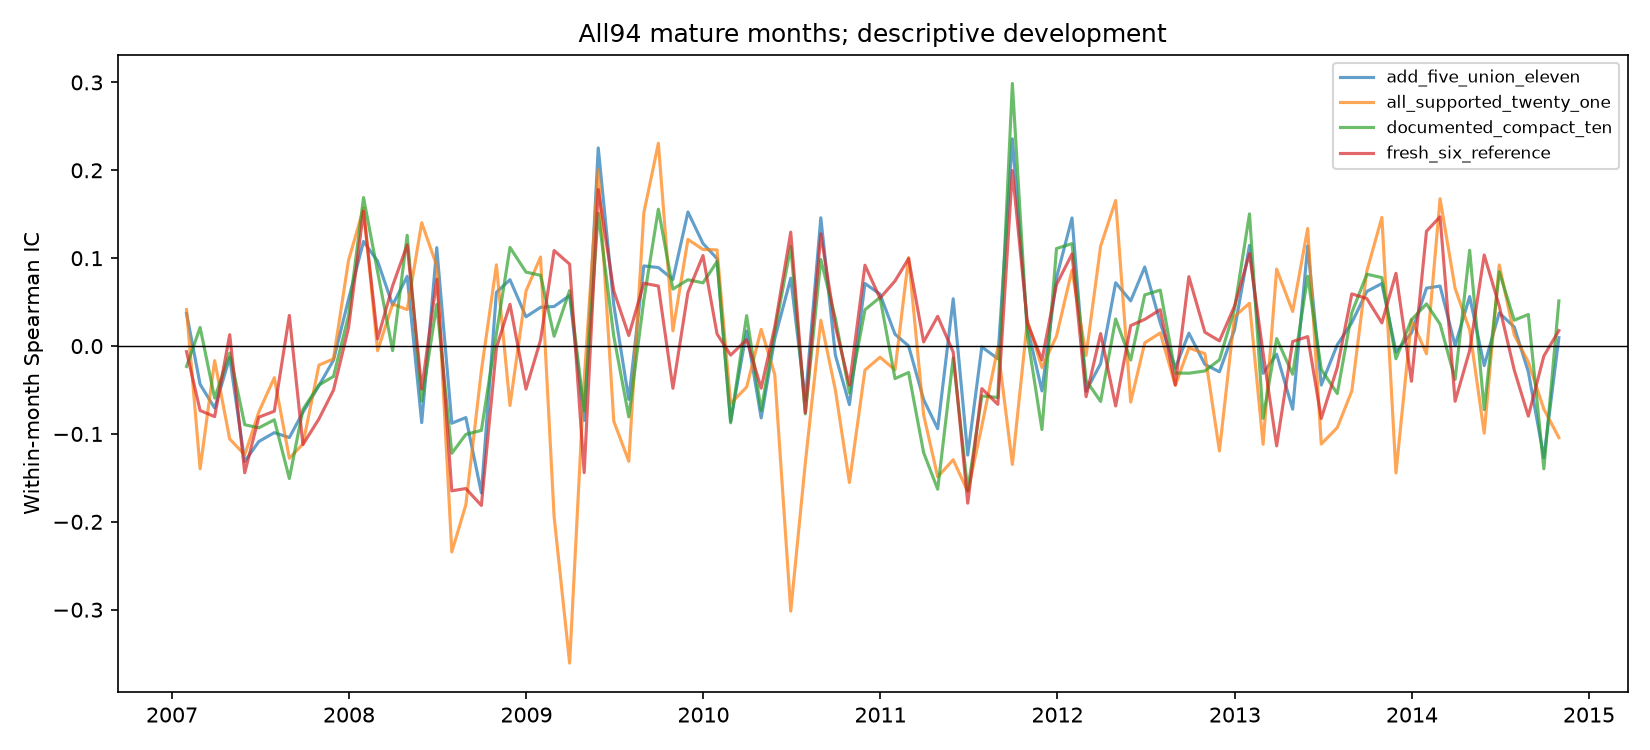

In [8]:
run_locked(r'''
import hashlib, json, os, time
from datetime import date
from pathlib import Path
context_raw = Path(os.environ['QUANTLAB_WIDER_CONTEXT']).read_bytes()
assert hashlib.sha256(context_raw).hexdigest() == os.environ['QUANTLAB_WIDER_CONTEXT_SHA']
context = json.loads(context_raw)
deadline = context['startup_deadline_monotonic']
def check_input_sources():
    paths = {str(Path(context['project'])/p): s for p,s in context['project_source_sha256'].items()}
    paths.update(context['input_container_sha256'])
    for name, expected_sha in paths.items():
        digest = hashlib.sha256()
        with Path(name).open('rb') as stream:
            while block := stream.read(4*1024*1024):
                assert time.monotonic() < deadline
                digest.update(block)
        assert digest.hexdigest() == expected_sha, 'Source/input postflight mismatch'
check_input_sources()
import platform, sys
from importlib.metadata import version
assert platform.python_version() == '3.12.15'
assert Path(os.path.abspath(sys.executable)) == Path(context['locked_interpreter'])
managed_root = Path(context['private_managed_root']).resolve()
assert Path(sys.executable).resolve().is_relative_to(managed_root)
assert {name:version(name) for name in context['runtime']} == context['runtime']
from quantlab.data.calendar import XNYSSchedule
from quantlab.stocks import development as d
from quantlab.stocks.wider_panel import PARENT_SHA
schedule = XNYSSchedule(date(1962,1,1), date(2018,12,31))
assert time.monotonic() < deadline
base_path = Path(context['project']) / 'configs/stock-development.toml'
base = d.load_spec(base_path)
from quantlab.data.archive import file_sha256
study = Path(context['study_root'])
manifest_sha = file_sha256(study/'manifest.json')
assert (study/'COMPLETE').read_text().strip() == manifest_sha
manifest = json.loads((study/'manifest.json').read_bytes())
for item in manifest['artifacts']:
    assert file_sha256(study/item['path']) == item['sha256']
comparison = json.loads((study/'paired-comparison.json').read_bytes())
print(json.dumps(comparison, indent=2))
print('Fixed controls:', json.loads((study/'control-metrics.json').read_bytes())[:5])
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
metrics = json.loads((study/'metrics.json').read_bytes())
fig, ax = plt.subplots(figsize=(11,5))
for arm in comparison['mean_ic']:
    rows = [r for r in metrics if r['arm_id']==arm and r['status']=='valid']
    ax.plot([date.fromisoformat(r['signal_session']) for r in rows],
            [r['ic'] for r in rows], label=arm, alpha=.7)
ax.axhline(0, color='black', linewidth=.7)
ax.set(ylabel='Within-month Spearman IC', title='All94 mature months; descriptive development')
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(Path(context['artifact_root'])/'wider-monthly-ic.png', dpi=150)
print('Verified study manifest:', manifest_sha)
check_input_sources()
workflow = Path(context['artifact_root']).parent
assert not (workflow/'NOTEBOOK_FAILURE.json').exists()
artifacts = []
for path in sorted(workflow.rglob('*')):
    if path.is_file():
        assert time.monotonic() < deadline
        artifacts.append({'path':path.relative_to(workflow).as_posix(),
                          'sha256':file_sha256(path), 'bytes':path.stat().st_size})
assert sum(r['bytes'] for r in artifacts) <= 20*1024**3
proof = {'complete':True, 'cells':384, 'paired_mature_months':94,
         'holdout_evaluated':False, 'study_manifest_sha256':manifest_sha,
         'source_plan_sha256':context['source_plan_sha256'], 'artifacts':artifacts}
proof_path = workflow/'workflow-manifest.json'
with proof_path.open('x') as stream:
    json.dump(proof, stream, sort_keys=True, indent=2)
assert time.monotonic() < deadline
(workflow/'NOTEBOOK_COMPLETE').write_text(file_sha256(proof_path)+'\n')
''')
from IPython.display import display, Image
context = json.loads(Path(CONTEXT_PATH).read_bytes())
display(Image(filename=str(Path(context['artifact_root'])/'wider-monthly-ic.png')))
